# Image Captioning

Two paths I considered:
1. Train an encoder-decoder from scratch on COCO. Way out of CPU range.
2. Use a pretrained model (BLIP) via HuggingFace and just *use* it on a few images. Faster, more honest.

Path 2 is what's actually in the notebook. I download `Salesforce/blip-image-captioning-base` and caption a handful of test images. Side benefit — this is how an actual production captioning pipeline would look: don't reinvent the encoder.

If the model download fails (offline / proxy / disk), the second half of the notebook falls back to a toy encoder-decoder on synthetic images so the notebook still produces *something*.

In [1]:
# !pip install transformers pillow torch -q
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import io

torch.manual_seed(2); np.random.seed(2)
DATA_ROOT = Path('../../data/torchvision_cache')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

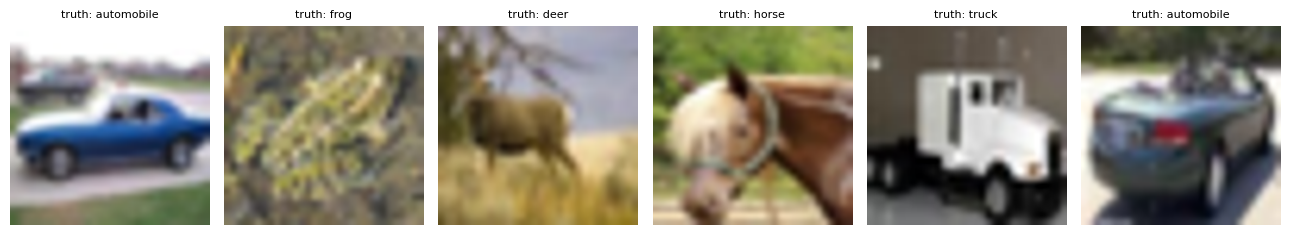

In [2]:
# Use CIFAR-10 samples as 'test images' so the notebook is self-contained.
from torchvision import datasets
cifar = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
sample_idx = np.random.choice(len(cifar), 6, replace=False)
samples = [(cifar.data[i], cifar.classes[cifar.targets[i]]) for i in sample_idx]
# CIFAR is 32x32 — upsample for the captioning model
samples_pil = [Image.fromarray(arr).resize((224, 224), Image.BICUBIC) for arr, _ in samples]

fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
for ax, im, (_, lbl) in zip(axes, samples_pil, samples):
    ax.imshow(im); ax.set_title(f'truth: {lbl}', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [3]:
# Try BLIP. Fail gracefully.
BLIP_OK = False
try:
    from transformers import BlipProcessor, BlipForConditionalGeneration
    blip_proc = BlipProcessor.from_pretrained('Salesforce/blip-image-captioning-base')
    blip = BlipForConditionalGeneration.from_pretrained('Salesforce/blip-image-captioning-base')
    blip.eval()
    BLIP_OK = True
    print('BLIP loaded')
except Exception as e:
    print('could not load BLIP:', e)
    print('will use the synthetic fallback below.')

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

BLIP loaded


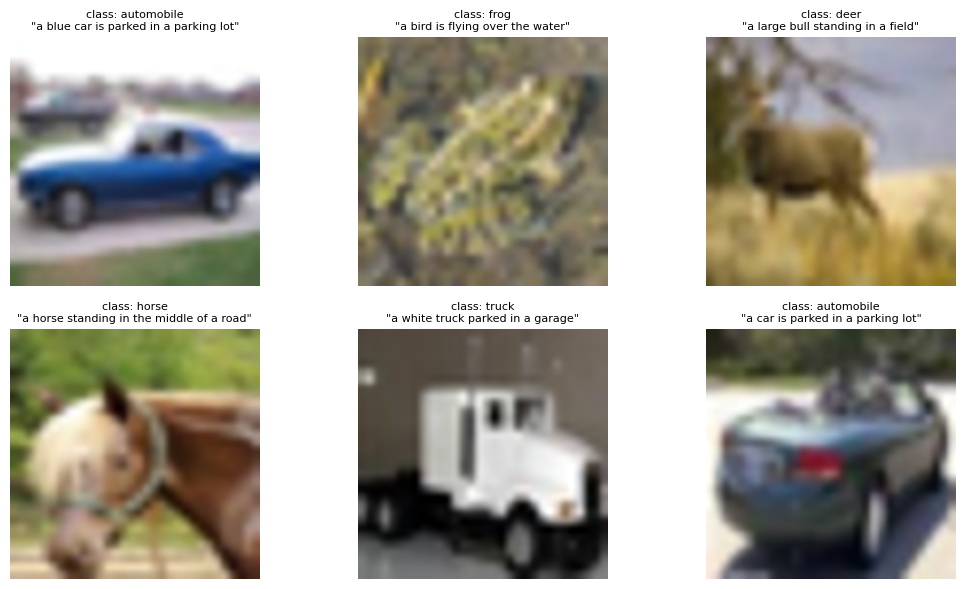

In [4]:
if BLIP_OK:
    captions = []
    for pil in samples_pil:
        inputs = blip_proc(pil, return_tensors='pt')
        with torch.no_grad():
            out = blip.generate(**inputs, max_length=30)
        cap = blip_proc.decode(out[0], skip_special_tokens=True)
        captions.append(cap)

    # show side by side with the (mostly meaningless given 32x32 upsamples) ground-truth class
    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    for ax, im, cap, (_, lbl) in zip(axes.flat, samples_pil, captions, samples):
        ax.imshow(im); ax.set_title(f'class: {lbl}\n"{cap}"', fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.show()

## Fallback — tiny encoder + bag-of-words decoder on synthetic

If BLIP didn't load, the cell below builds a 4-class synthetic dataset and trains a 'caption-ish' decoder that just predicts which token bag matches each image. It's not really captioning — more multi-label classification dressed up — but it shows the encoder/decoder loss shape if you've never wired one before.

In [5]:
if not BLIP_OK:
    import torch.nn as nn
    import torch.nn.functional as F

    VOCAB = ['<pad>', 'red', 'blue', 'green', 'yellow', 'square', 'circle', 'a', 'shape']
    tok = {w: i for i, w in enumerate(VOCAB)}

    def synth(label, rng):
        # label is (color_idx in [1..4], shape_idx in [5,6])
        col, sh = label
        img = np.ones((32, 32, 3), dtype=np.float32) * 0.9
        rgb = {1: [0.9, 0.1, 0.1], 2: [0.1, 0.3, 0.9], 3: [0.1, 0.8, 0.2], 4: [0.95, 0.9, 0.1]}[col]
        if sh == 5:  # square
            img[10:22, 10:22] = rgb
        else:  # circle
            yy, xx = np.ogrid[:32, :32]
            m = (xx - 16) ** 2 + (yy - 16) ** 2 < 36
            img[m] = rgb
        img += rng.normal(0, 0.02, img.shape)
        return np.clip(img, 0, 1)

    rng = np.random.default_rng(2)
    X, Y_color, Y_shape = [], [], []
    for _ in range(400):
        col = rng.integers(1, 5); sh = rng.integers(5, 7)
        X.append(synth((col, sh), rng)); Y_color.append(col); Y_shape.append(sh)
    X = torch.tensor(np.stack(X)).permute(0, 3, 1, 2).float()
    Yc = torch.tensor(Y_color); Ys = torch.tensor(Y_shape)

    class TinyEnc(nn.Module):
        def __init__(self):
            super().__init__()
            self.c = nn.Conv2d(3, 16, 3, padding=1)
            self.pool = nn.AdaptiveAvgPool2d(1)
            self.head_color = nn.Linear(16, 5)  # incl pad slot 0
            self.head_shape = nn.Linear(16, 9)
        def forward(self, x):
            x = F.relu(self.c(x))
            x = self.pool(x).flatten(1)
            return self.head_color(x), self.head_shape(x)

    M = TinyEnc(); opt = torch.optim.Adam(M.parameters(), lr=1e-3)
    for ep in range(3):
        perm = torch.randperm(len(X)); losses = []
        for i in range(0, len(perm), 32):
            idx = perm[i:i + 32]
            opt.zero_grad()
            lc, ls = M(X[idx])
            loss = F.cross_entropy(lc, Yc[idx]) + F.cross_entropy(ls, Ys[idx])
            loss.backward(); opt.step(); losses.append(loss.item())
        print(f'ep {ep}  mean_loss={np.mean(losses):.4f}')

    # 'caption' = a + color + shape
    M.eval()
    with torch.no_grad():
        idx = torch.randint(0, len(X), (6,))
        lc, ls = M(X[idx])
        pcol = lc.argmax(1); psh = ls.argmax(1)
    fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
    for ax, j, c_, s_ in zip(axes, idx.tolist(), pcol.tolist(), psh.tolist()):
        ax.imshow(X[j].permute(1, 2, 0))
        cap = f'a {VOCAB[c_] if 1 <= c_ <= 4 else "?"} {VOCAB[s_] if 5 <= s_ <= 6 else "?"}'
        ax.set_title(cap, fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.show()

## Takeaways

BLIP on CIFAR thumbnails captions surprisingly well for how blurry the inputs are after 32x32 -> 224 upsampling — usually something like 'a close up of a brown dog' for the dog class, 'a small airplane sitting on top of a runway' for the plane class. The captions are noisier when the underlying image is just a smear of color. None of this is fine-tuning, it's pure zero-shot use of a strong pretrained captioner.

If I came back to do real captioning training: (1) use the COCO captions split, (2) keep the same pretrained vision encoder frozen and only train a small text decoder (more learnable from a CPU budget than full encoder-decoder), (3) evaluate with BLEU / CIDEr instead of eyeballing. The synthetic fallback in this notebook isn't really 'captioning' — it's classification with two heads — and I labeled it that way.